In [85]:
%pip install -q matplotlib tensorflow numpy pillow scikit-image

Note: you may need to restart the kernel to use updated packages.


# Module 8 Capstone Project Part 1

> Submitted by Phillip Amir Esguerra

# 1. Import Libraries

In [86]:
import numpy as np
import matplotlib.pyplot as plt
import math
from PIL import Image
import tensorflow as tf
from skimage import data, color

# Load and display sample image

In [87]:
input_image_path = r"./input.png"
input_image = Image.open(input_image_path)

input_image_rgb = input_image.convert("RGB")
input_image_float = np.array(input_image_rgb).astype(np.float32) / 255.0

timesteps = [0.1, 0.3, 0.6, 0.9]
# timesteps = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

In [88]:
def display_image(image_as_float, title="", size=(5, 5)):
    plt.figure(figsize=size)
    plt.imshow(image_as_float)
    plt.axis('off')
    plt.title(title)
    plt.show()
    
    return image_as_float

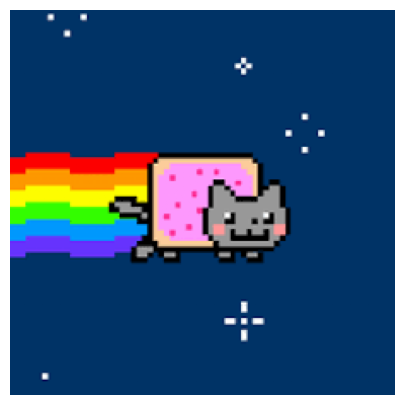

In [89]:
_ = display_image(input_image_float)

# Adding Noise

In [90]:
def add_noise(image, timestep): # deepfrying :)
    alpha_bar = 1 - timestep
    noise = np.random.normal(0, 1, image.shape)
    noisy_image = np.sqrt(alpha_bar) * image + np.sqrt(1 - alpha_bar) * noise
    return np.clip(noisy_image, 0, 1)

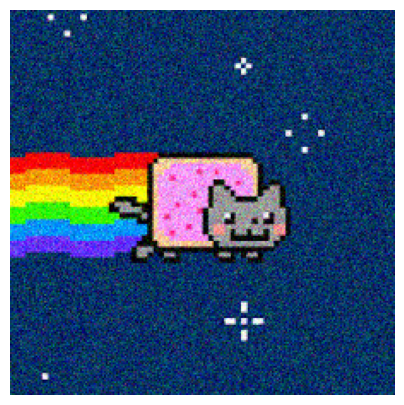

In [91]:
_ = display_image(add_noise(image=input_image_float, timestep=0.01))

# Visualizing noise by timestep

In [92]:
def display_noise_by_timestep(image, timesteps, title="", size=(15, 4)):
    figure, axes = plt.subplots(1, len(timesteps), figsize=size)
    axes = axes.flatten()
    figure.suptitle(title)
    for i, t in enumerate(timesteps):
        noisy_image = add_noise(image=image, timestep=t)
        axes[i].imshow(noisy_image)
        axes[i].set_title(f"t: {t:.2}")
        axes[i].axis('off')

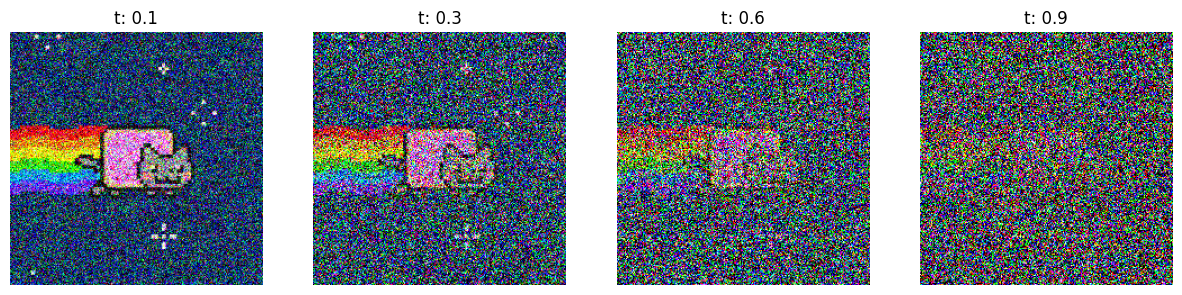

In [93]:
display_noise_by_timestep(image=input_image_float, timesteps=timesteps)

# Implementing Noise Schedules

In [94]:
def linear_diffusion_schedule(diffusion_times):
    min_rate = 0.0001
    max_rate = 0.02
    betas = min_rate + diffusion_times * (max_rate - min_rate)
    alphas = 1 - betas
    alpha_bars = tf.math.cumprod(alphas)
    signal_rates = tf.sqrt(alpha_bars)
    noise_rates = tf.sqrt(1 - alpha_bars)
    return noise_rates, signal_rates

def cosine_diffusion_schedule(diffusion_times):
    signal_rates = tf.cos(diffusion_times * math.pi / 2)
    noise_rates = tf.sin(diffusion_times * math.pi / 2)
    return noise_rates, signal_rates

def exponential_diffusion_schedule(diffusion_times):
    signal_rates = tf.exp(-diffusion_times)
    noise_rates = 1 - signal_rates
    return noise_rates, signal_rates

def interpolated_timesteps(diffusion_times, noise_rates, timesteps):
    diffusion_times_np = diffusion_times.numpy() if hasattr(diffusion_times, 'numpy') else diffusion_times
    noise_rates_np = noise_rates.numpy() if hasattr(noise_rates, 'numpy') else noise_rates

    # Interpolate
    interpolated_noise_rates = np.interp(timesteps, diffusion_times_np, noise_rates_np)
    return interpolated_noise_rates ** 2


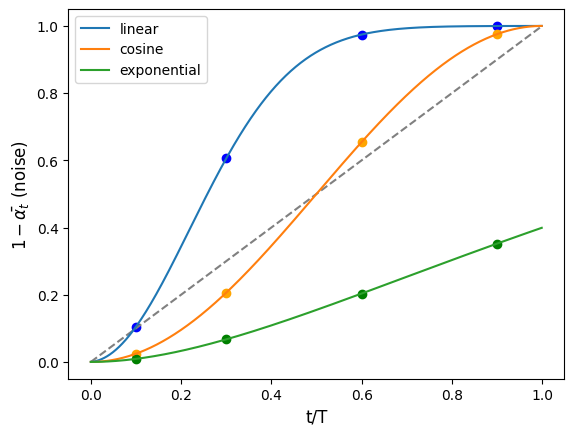

In [95]:
T = 1000
diffusion_times = tf.convert_to_tensor([x / T for x in range(T)])
plt.plot(diffusion_times, [x / T for x in range(T)], '--', color='gray')

linear_noise_rates, _ = linear_diffusion_schedule(diffusion_times)
plt.plot(diffusion_times, linear_noise_rates**2, linewidth=1.5, label="linear")
linear_schedules = interpolated_timesteps(diffusion_times, linear_noise_rates, timesteps)
plt.scatter(timesteps, linear_schedules, color='blue')

cosine_noise_rates, _ = cosine_diffusion_schedule(diffusion_times)
plt.plot(diffusion_times, cosine_noise_rates**2, linewidth=1.5, label="cosine")
cosine_schedules = interpolated_timesteps(diffusion_times, cosine_noise_rates, timesteps)
plt.scatter(timesteps, cosine_schedules, color='orange')

exponential_noise_rates, _ = exponential_diffusion_schedule(diffusion_times)
plt.plot(diffusion_times, exponential_noise_rates**2, linewidth=1.5, label="exponential")
exponential_schedules = interpolated_timesteps(diffusion_times, exponential_noise_rates, timesteps)
plt.scatter(timesteps, exponential_schedules, color='green')

plt.xlabel("t/T", fontsize=12)
plt.ylabel(r"$1-\bar{\alpha_t}$ (noise)", fontsize=12)
plt.legend()
plt.show()

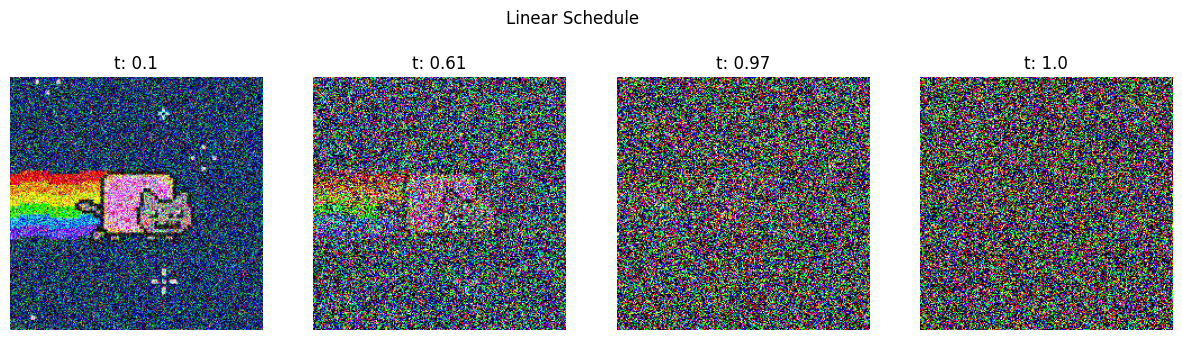

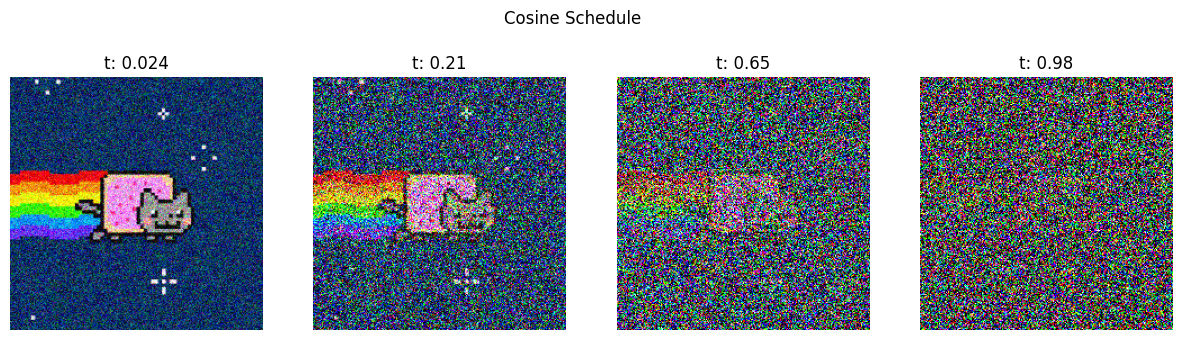

In [96]:
display_noise_by_timestep(
    image=input_image_float, 
    timesteps=linear_schedules, 
    title="Linear Schedule")

display_noise_by_timestep(
    image=input_image_float, 
    timesteps=cosine_schedules, 
    title="Cosine Schedule")
